In [8]:
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.constants import physical_constants
from scipy.optimize import curve_fit
import pandas as pd
from scipy.signal import find_peaks
from lpsd import lpsd
from scipy.stats import linregress  
from scipy.signal import welch
from scipy.special import voigt_profile

# Laser frequency stabilization

In this hands-on session, we will use experimental data to study laser-frequency stabilization with the [Pound-Drever-Hall (PDH) technique](https://doi.org/10.1364/OL.19.000898). We will:

1. characterize the reference cavity,
2. convert the PDH error signal into laser-frequency deviations,
3. examine how PID settings affect the feedback bandwidth, and
4. estimate the laser lineshape and linewidth from the measured frequency noise.

The laser is a diode laser near 493 nm, used to drive the $S_{1/2} \rightarrow P_{1/2}$ transition in $^{138}\mathrm{Ba}^+$ ions. This transition supports laser cooling, fluorescence detection, and state manipulation.

The atomic transition has a linewidth of approximately 20 MHz, much broader than the laser linewidth measured here (of order 100 kHz). The lock is therefore used primarily to keep the laser frequency centered over time, rather than to make the laser narrow enough to resolve the atomic transition.

The data files are in [`../data/`](../data/). Keep track of units throughout: the cavity scans are calibrated in MHz, while the frequency-noise analysis ultimately uses Hz.

# Cavity properties

An optical cavity provides a frequency reference for the lock. We first characterize its free spectral range (FSR), resonance linewidth, length, and finesse.

The **free spectral range** is the frequency spacing between adjacent longitudinal modes:

$$\mathrm{FSR} = \frac{c}{2L},$$

where $c$ is the speed of light and $L$ is the cavity length. The **cavity linewidth** $\Delta\nu$ is the full width at half maximum (FWHM) of one resonance. The **finesse** is

$$\mathcal{F} = \frac{\mathrm{FSR}}{\Delta\nu}.$$

For a simple two-mirror cavity with power reflectivity $R$, one commonly used approximation is

$$\mathcal{F} \approx \frac{\pi\sqrt{R}}{1-R}.$$

A higher finesse gives narrower resonances and therefore a steeper frequency discriminator. The analysis below uses the transmission scans in [`../data/cavity-properties/`](../data/cavity-properties/).

In [9]:
c = physical_constants['speed of light in vacuum'][0]

folder = '../data/cavity-properties'
df_wide = pd.read_csv(f'{folder}/wide-scan.csv', delimiter=';')
df_narrow = pd.read_csv(f'{folder}/narrow-scan.csv', delimiter=';')

# normalize and massage the data 
transmission_narrow = (df_narrow['transmission-voltage'] - np.min(df_narrow['transmission-voltage'])) / (np.max(df_narrow['transmission-voltage']) - np.min(df_narrow['transmission-voltage']))
pdh_error_narrow = df_narrow['pdh-error'] / np.max(np.abs(df_narrow['pdh-error']))
piezo_voltage_narrow = df_narrow['piezo-voltage']
piezo_voltage_center = piezo_voltage_narrow[np.argmax(transmission_narrow)]
piezo_voltage_narrow = piezo_voltage_narrow - piezo_voltage_center

transmission_wide = (df_wide['transmission-voltage'] - np.min(df_wide['transmission-voltage'])) / (np.max(df_wide['transmission-voltage']) - np.min(df_wide['transmission-voltage']))
pdh_error_wide = df_wide['pdh-error'] / np.max(np.abs(df_wide['pdh-error']))
piezo_voltage_wide = df_wide['piezo-voltage']
piezo_voltage_center = piezo_voltage_wide[np.argmax(transmission_wide[:len(transmission_wide)//2])]
piezo_voltage_wide = piezo_voltage_wide - piezo_voltage_center

## Plot the transmission and error signals as function of the piezo voltage

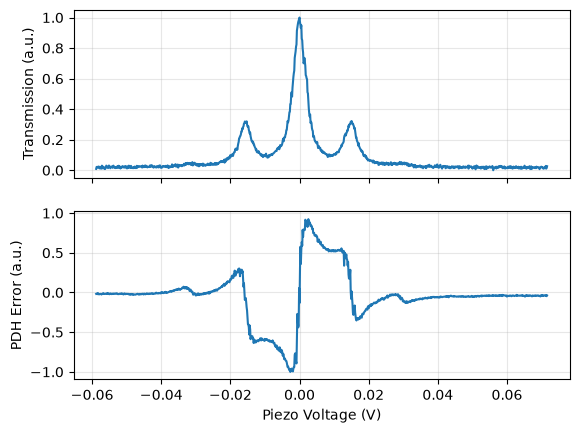

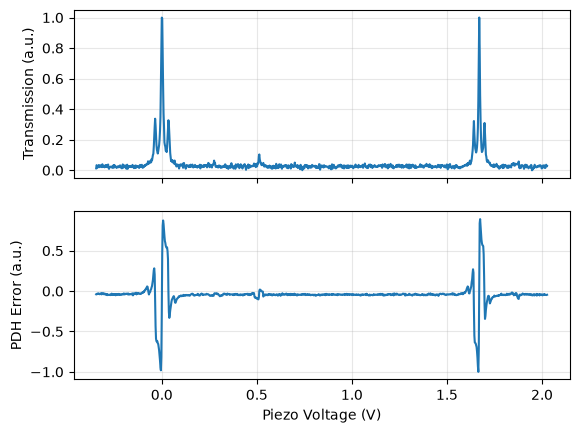

In [10]:
# plot the transmission and PDH error signals
fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(piezo_voltage_narrow, transmission_narrow)
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(piezo_voltage_narrow, pdh_error_narrow)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Piezo Voltage (V)')
for ax in axs:
    ax.grid(True, alpha=0.3)
plt.show()

fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(piezo_voltage_wide, transmission_wide)
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(piezo_voltage_wide, pdh_error_wide)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Piezo Voltage (V)')
for ax in axs:
    ax.grid(True, alpha=0.3)
plt.show()

## Convert piezo voltage to frequency

The piezo voltage scans the laser across the cavity resonances, but the horizontal axis we need is frequency. The modulation sidebands are separated from the carrier by 25 MHz, providing a frequency reference. Identify the carrier and sideband peaks, measure their spacing in piezo voltage, and use that spacing to calibrate both scans.

The calibration is approximately linear over each scan. Check the peak markers and the resulting frequency axis before using the data for fits.

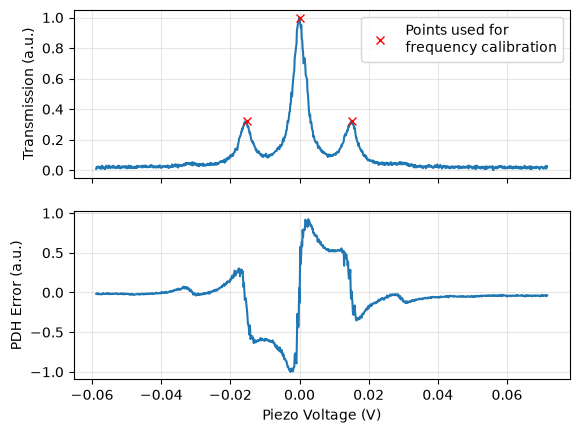

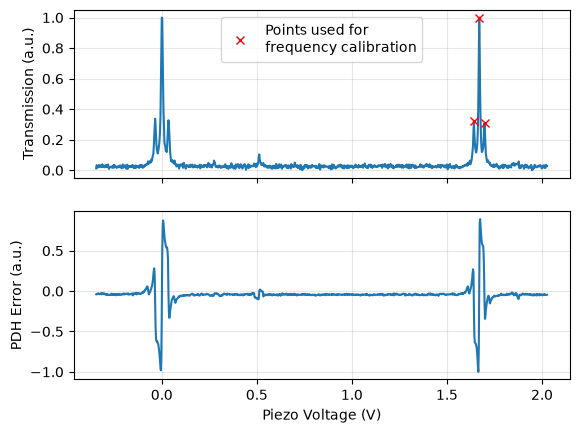

In [11]:
sideband_spacing_frequency = 25 # MHz

peak_indicies_narrow = find_peaks(transmission_narrow, height=0.2, distance=100)[0]
peak_indicies_wide = find_peaks(transmission_wide[len(transmission_wide)//2:], height=0.2, distance=10)[0]

# plot the transmission and PDH error signals
fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(piezo_voltage_narrow, transmission_narrow)
axs[0].plot(piezo_voltage_narrow[peak_indicies_narrow], transmission_narrow[peak_indicies_narrow], 'rx', label='Points used for\nfrequency calibration')
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(piezo_voltage_narrow, pdh_error_narrow)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Piezo Voltage (V)')
axs[0].legend()
for ax in axs:
    ax.grid(True, alpha=0.3)
plt.show()

fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(piezo_voltage_wide, transmission_wide)
axs[0].plot(piezo_voltage_wide[peak_indicies_wide+len(piezo_voltage_wide)//2], transmission_wide[peak_indicies_wide+len(transmission_wide)//2], 'rx', label='Points used for\nfrequency calibration')
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(piezo_voltage_wide, pdh_error_wide)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Piezo Voltage (V)')
axs[0].legend()
for ax in axs:
    ax.grid(True, alpha=0.3)
plt.show()


sideband_spacing_voltage_narrow = np.mean([piezo_voltage_narrow[peak_indicies_narrow[i+1]] - piezo_voltage_narrow[peak_indicies_narrow[i]] for i in range(len(peak_indicies_narrow)-1)])
frequency_narrow = piezo_voltage_narrow * sideband_spacing_frequency/sideband_spacing_voltage_narrow

sideband_spacing_voltage_wide = np.mean([piezo_voltage_wide[peak_indicies_wide[i+1]] - piezo_voltage_wide[peak_indicies_wide[i]] for i in range(len(peak_indicies_wide)-1)])
frequency_wide = piezo_voltage_wide * sideband_spacing_frequency/sideband_spacing_voltage_wide

## Plot the transmission and error signals as function of the frequency

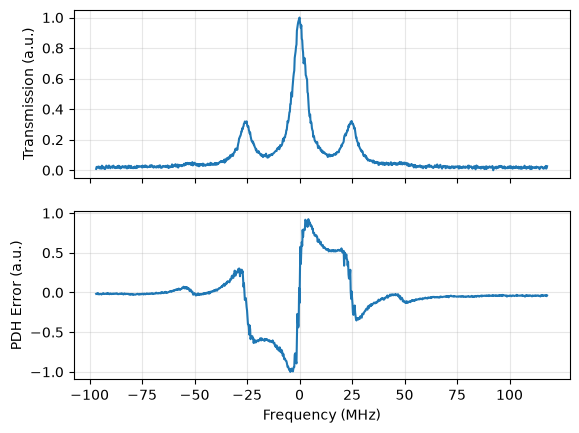

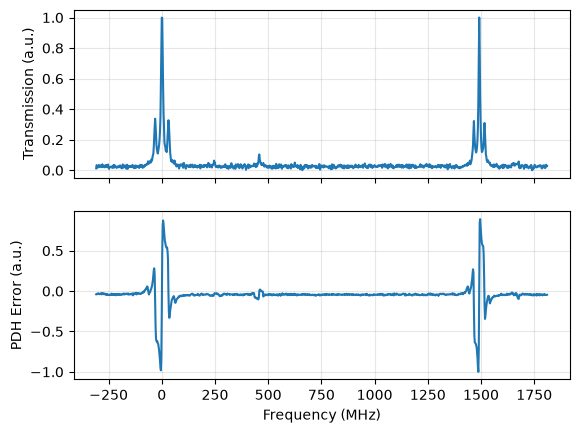

In [12]:
fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(frequency_narrow, transmission_narrow)
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(frequency_narrow, pdh_error_narrow)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Frequency (MHz)')
for ax in axs:
    ax.grid(True, alpha=0.3)
    ax.set_xticks(np.arange(-100, 125, 25))
plt.show()

fig, axs = plt.subplots(2, 1, sharex=True)
axs[0].plot(frequency_wide, transmission_wide)
axs[0].set_ylabel('Transmission (a.u.)')
axs[1].plot(frequency_wide, pdh_error_wide)
axs[1].set_ylabel('PDH Error (a.u.)')
axs[1].set_xlabel('Frequency (MHz)')
for ax in axs:
    ax.grid(True, alpha=0.3)
    ax.set_xticks(np.arange(-250, 2000, 250))
plt.show()

## Analyse the transmission spectra

### Cavity linewidth

Fit the central transmission peak in the narrow scan with a Lorentzian and extract its FWHM. Select a fitting window that excludes the sidebands. The covariance matrix returned by `curve_fit` provides an estimate of the linewidth uncertainty.

The linewidth is the full width at half maximum, not the half-width parameter used inside the Lorentzian model.

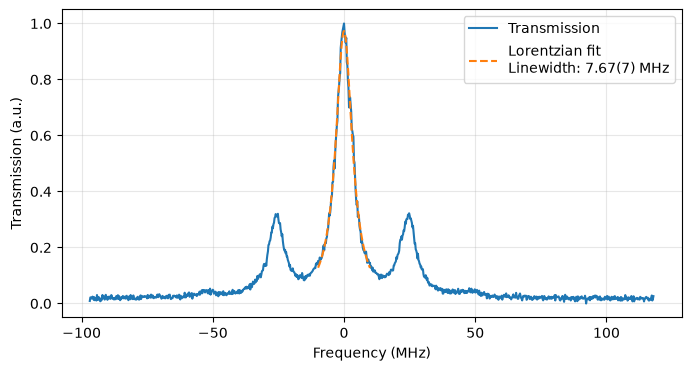

In [13]:
def lorentzian(x, x0, gamma, A):
    return A * gamma**2 / ((x - x0)**2 + gamma**2)

indicies_for_fit = np.where(np.abs(frequency_narrow) < 10)[0]
frequency_for_fit = frequency_narrow[indicies_for_fit]
transmission_for_fit = transmission_narrow[indicies_for_fit]

popt, pcov = curve_fit(lorentzian, frequency_for_fit, transmission_for_fit, p0=[0, 1, 1])
x0, gamma, A = popt
cavity_linewidth = 2 * gamma
linewidth_uncertainty = 2 * np.sqrt(pcov[1, 1])

fig, axs = plt.subplots(1, 1, figsize=(8, 4))
axs.plot(frequency_narrow, transmission_narrow, label='Transmission')
axs.plot(frequency_for_fit, lorentzian(frequency_for_fit, *popt), label=f'Lorentzian fit\nLinewidth: {cavity_linewidth:.2f}({linewidth_uncertainty*100:.0f}) MHz', linestyle='--')
axs.set_ylabel('Transmission (a.u.)')
axs.set_xlabel('Frequency (MHz)')
axs.legend()
axs.grid(True, alpha=0.3)
plt.show()

### Cavity FSR, length, and finesse
Extract the cavity free spectral range (FSR) from the frequency difference between adjacent transmission peaks in the wide scan.

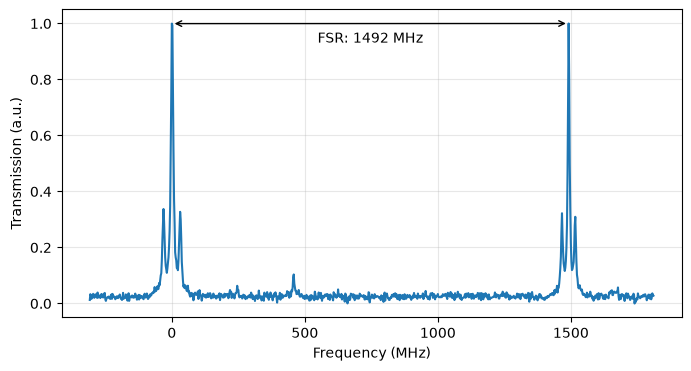

In [14]:
peaks = find_peaks(transmission_wide, height=0.5)[0]
fsr = np.diff(frequency_wide[peaks])[0]

fig, axs = plt.subplots(1, 1, figsize=(8, 4))
axs.plot(frequency_wide, transmission_wide, label='Transmission')
# make an arrow between the first two peaks to indicate the FSR
axs.annotate('', xy=(frequency_wide[peaks[1]], transmission_wide[peaks[1]]), xytext=(frequency_wide[peaks[0]], transmission_wide[peaks[0]]),arrowprops=dict(arrowstyle='<->', color='black'))
mid_x = (frequency_wide[peaks[0]] + frequency_wide[peaks[1]]) / 2
mid_y = (transmission_wide[peaks[0]] + transmission_wide[peaks[1]]) / 2 - 0.08
axs.text(mid_x, mid_y, f'FSR: {fsr:.0f} MHz', color='black', ha='center', va='bottom')
axs.set_ylabel('Transmission (a.u.)')
axs.set_xlabel('Frequency (MHz)')
axs.grid(True, alpha=0.3)
plt.show()

In [15]:
cavity_length = c / (2 * fsr * 1e6)  # in meters 
print(f"Cavity length: {cavity_length*1e3:.0f} mm")
cavity_finesse = fsr/cavity_linewidth  # assuming cavity_linewidth is defined elsewhere
cavity_finesse_uncertainty = cavity_finesse * linewidth_uncertainty / cavity_linewidth
print(f"Cavity finesse: {cavity_finesse:.0f}({cavity_finesse_uncertainty:.0f})")

Cavity length: 100 mm
Cavity finesse: 194(2)


Note that a finesse of around 200 makes this a low-finesse cavity. This laser is used to drive a wide atomic transition, so we don't care much about having a very narrow linewidth laser. 

We have another cavity in our lab with a finesse around 150'000, which is considered a high-finesse cavity. This type of cavity is suitable for experiments requiring very narrow linewidth lasers, such as precision spectroscopy of narrow atomic transitions.

# Feedback-loop bandwidth and PID settings

The feedback controller acts on the PDH error signal. Changing the proportional gain changes which frequency components are suppressed and which are amplified. We compare power spectral densities (PSDs) measured at three controller settings.

A peak in the spectrum near the feedback bandwidth is called a **servo bump**. It indicates that the loop is approaching its stability limit and provides a rough estimate of the control-loop bandwidth. Compare the spectra and consider the trade-off between low-frequency noise suppression and high-frequency amplification.

The corresponding data are in [`../data/servo-bump/`](../data/servo-bump/).

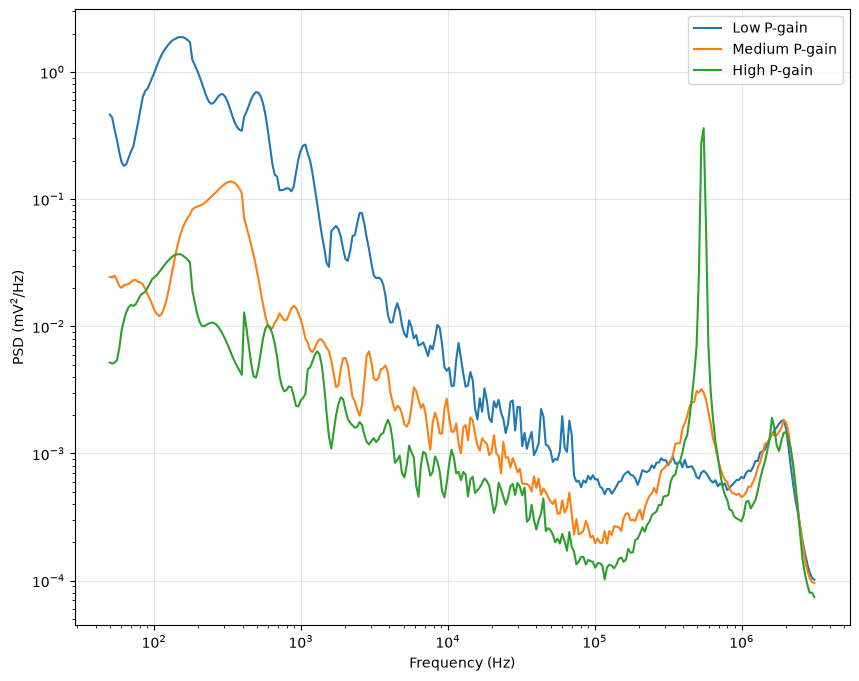

In [16]:
folder = '../data/servo-bump'
file_names = ['low-P.CSV', 'medium-P.CSV', 'high-P.CSV']
labels = ['Low P-gain', 'Medium P-gain', 'High P-gain']
fig, axs = plt.subplots(1, 1, figsize=(10, 8))
for file_name in file_names:
    df_locked = pd.read_csv(folder + '/' + file_name)
    time_locked = df_locked['time(s)'].to_numpy() # in ms
    voltage_fluctuations_in_time = df_locked['error-signal(V)'].to_numpy()*1e3 # in mV  
    frequencies, psd = lpsd(
        voltage_fluctuations_in_time,
        fs=1 / np.mean(np.diff(time_locked)),
        Jdes=300,
        Kdes=30,
        Kmin=1,
        xi=0.0,
    )
    axs.loglog(frequencies, psd, label=labels[file_names.index(file_name)])
axs.set_xlabel('Frequency (Hz)')
axs.set_ylabel(r'PSD (mV$^2$/Hz)')
axs.grid(True, alpha=0.3)
axs.legend()
plt.show()


We see that by increasing the P-gain, we reduce the noise at low frequencies, but this comes at the cost of increased noise at higher frequencies. Which P-gain to choose depends on the specific requirements of the application. Typically, the atomic transitions driven by this laser happen at timescales of tens of microseconds, so we care more about the noise at 100 kHz and above. 

We can also clearly recognize the servo bump in the PSD around 500 kHz, which is the bandwidth of the feedback loop.

# Frequency noise and laser linewidth

In this section we infer the laser's frequency noise from the locked PDH error signal. The workflow follows the optical-spectrum method described in the [linewidth analyser manual](../litterature/lwa-10k-100k-manual-2025-06_0007.pdf), especially pages 25–33.

We first calibrate error-signal voltage to frequency using the unlocked scan. We then calculate the frequency-noise density and reconstruct the optical lineshape from the integrated frequency fluctuations. Finally, we fit the central lineshape with a Voigt profile.

A linewidth depends on the observation time and measurement bandwidth. Treat the fitted value as the linewidth observed for this record, not as a universal property of the diode.

In [17]:
folder = '../data/frequency-noise'
df_locked = pd.read_csv(folder + '/locked-error-signal.csv')
df_unlocked = pd.read_csv(folder + '/unlocked-error-signal.csv')
time_locked = df_locked['time(s)'].to_numpy() # in s
time_unlocked = df_unlocked['time(s)'].to_numpy() # in s
error_signal_locked = df_locked['error-signal(V)'].to_numpy()*1e3 # in mV
error_signal_unlocked = df_unlocked['error-signal(V)'].to_numpy()*1e3 # in mV

sideband_spacing_frequency = 25 # in MHz

## Calibrate frequency deviations from the PDH error signal

Use the unlocked error signal to locate the carrier and the two modulation sidebands. Their known 25 MHz spacing converts the time axis into frequency. In the central, approximately linear part of the PDH discriminator, the error-signal voltage is proportional to frequency deviation.

The code below shows one implementation of this calibration. Inspect the selected regions and markers: choosing a different region can change the calibration.

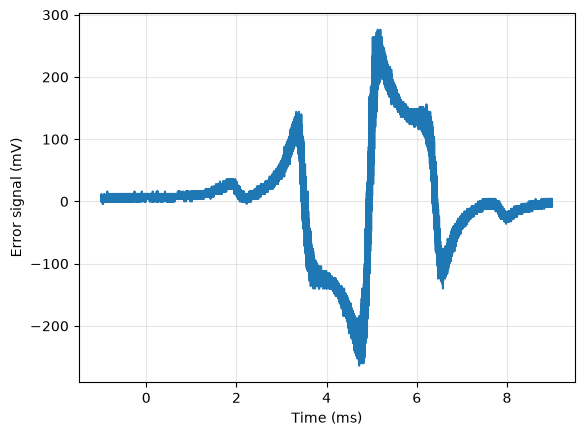

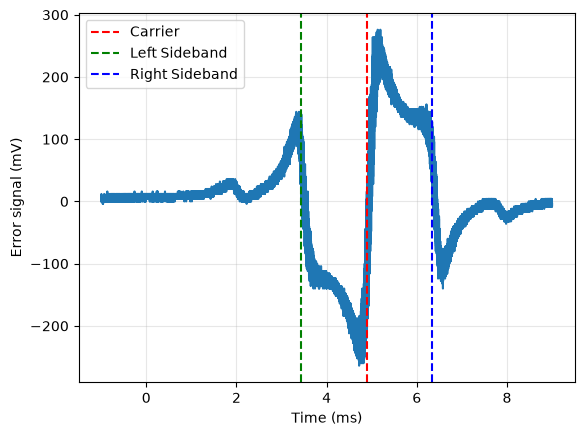

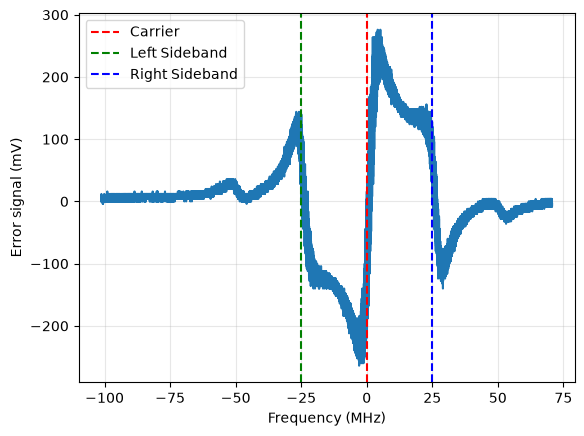

In [18]:
fig, axs = plt.subplots(1, 1)
axs.plot(time_unlocked*1e3, error_signal_unlocked)
axs.set_xlabel('Time (ms)')
axs.set_ylabel('Error signal (mV)')
axs.grid(alpha=0.3)
plt.show()

# filter out the carrier and sidebands based on the time ranges
carrier_indices = np.where((time_unlocked>4*1e-3) & (time_unlocked<6*1e-3))[0]
left_sideband_indices = np.where((time_unlocked>3*1e-3) & (time_unlocked<4*1e-3))[0]
right_sideband_indices = np.where((time_unlocked>6*1e-3) & (time_unlocked<7*1e-3))[0]

# find the time stamps corresponding to the minimum error signal within each region
carrier_time = time_unlocked[carrier_indices][np.argmin(np.abs(error_signal_unlocked[carrier_indices]))]
left_sideband_time = time_unlocked[left_sideband_indices][np.argmin(np.abs(error_signal_unlocked[left_sideband_indices]))]
right_sideband_time = time_unlocked[right_sideband_indices][np.argmin(np.abs(error_signal_unlocked[right_sideband_indices]))]

fig, axs = plt.subplots(1, 1)
axs.plot(time_unlocked*1e3, error_signal_unlocked)
axs.axvline(carrier_time*1e3, color='r', linestyle='--', label='Carrier')
axs.axvline(left_sideband_time*1e3, color='g', linestyle='--', label='Left Sideband')
axs.axvline(right_sideband_time*1e3, color='b', linestyle='--', label='Right Sideband')
axs.legend()
axs.set_xlabel('Time (ms)')
axs.set_ylabel('Error signal (mV)')
axs.grid(alpha=0.3)
plt.show()


sideband_spacing_time = (right_sideband_time - left_sideband_time)/2
time_to_frequency_conversion = sideband_spacing_frequency / sideband_spacing_time # MHz/ms
carrier_frequency = carrier_time * time_to_frequency_conversion
left_sideband_frequency = left_sideband_time * time_to_frequency_conversion
right_sideband_frequency = right_sideband_time * time_to_frequency_conversion
frequency_unlocked = time_unlocked * time_to_frequency_conversion - carrier_frequency # center around the carrier


fig, axs = plt.subplots(1, 1)
axs.plot(frequency_unlocked, error_signal_unlocked)
axs.axvline(0, color='r', linestyle='--', label='Carrier')
axs.axvline(left_sideband_frequency - carrier_frequency, color='g', linestyle='--', label='Left Sideband')
axs.axvline(right_sideband_frequency - carrier_frequency, color='b', linestyle='--', label='Right Sideband')
axs.legend()
axs.set_xlabel('Frequency (MHz)')
axs.set_ylabel('Error signal (mV)')
axs.grid(alpha=0.3)
plt.show()


When the laser is locked, the error signal should remain within the discriminator's linear range. In that range, a voltage fluctuation maps directly to a frequency fluctuation. We estimate the conversion factor from a linear fit around the lock point.

The conversion is only valid locally. Large excursions outside the chosen region should not be interpreted with the same slope.

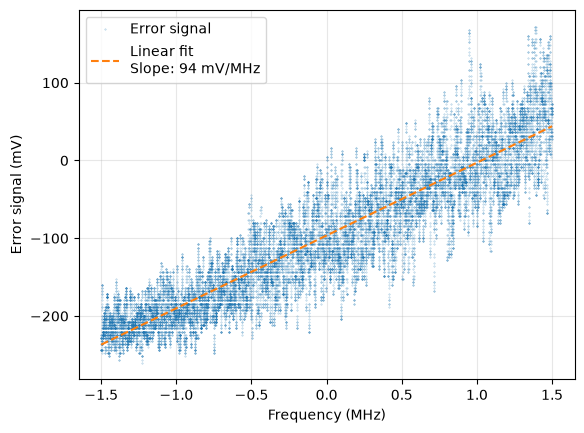

In [19]:
# Use the central part of the error signal to get the linear relation between voltage and frequency.
linear_region = 1.5

central_indices = np.where((frequency_unlocked > -linear_region) & (frequency_unlocked < linear_region))[0]
frequency_central = frequency_unlocked[central_indices]
error_signal_central = error_signal_unlocked[central_indices]
line = linregress(frequency_central, error_signal_central)
voltage_to_frequency_factor = 1/line.slope

fig, axs = plt.subplots(1, 1)
axs.plot(frequency_central, error_signal_central, 'o', label='Error signal', alpha=0.5, markersize=0.3)
axs.plot(frequency_central, (line.intercept + line.slope * frequency_central), '--', label=f'Linear fit\nSlope: {line.slope:.0f} mV/MHz')
axs.set_xlabel('Frequency (MHz)')
axs.set_ylabel('Error signal (mV)')
axs.grid(alpha=0.3)
axs.legend()
plt.show()

## Frequency deviations in time over a 4 ms interval

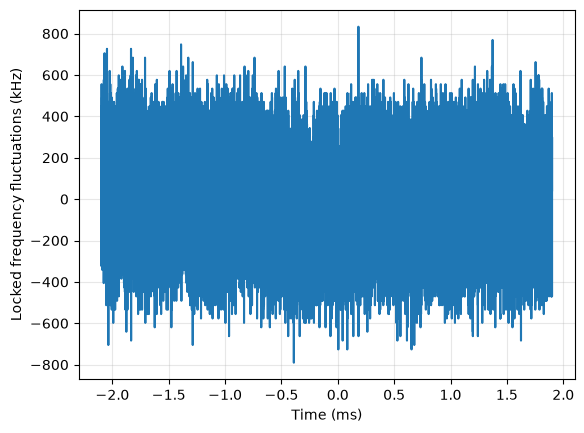

In [20]:
# look at the frequency fluctuations in time
frequency_fluctuations_in_time = error_signal_locked * voltage_to_frequency_factor

fig, axs = plt.subplots(1, 1)
axs.plot(time_locked*1e3, frequency_fluctuations_in_time*1e3)
axs.set_xlabel('Time (ms)')
axs.set_ylabel('Locked frequency fluctuations (kHz)')
axs.grid(alpha=0.3)
plt.show()

## Frequency noise density analysis

The time trace shows the largest frequency excursions, but it does not reveal how the noise is distributed over Fourier frequency. A frequency-noise density (FND) does: its units are $\mathrm{Hz}/\sqrt{\mathrm{Hz}}$, and integrating its power over a bandwidth gives a frequency variance.

The oscilloscope bandwidth is 5 MHz, so this measurement cannot characterize noise above that limit. Peaks in the FND can point to technical noise sources or resonances in the feedback electronics.

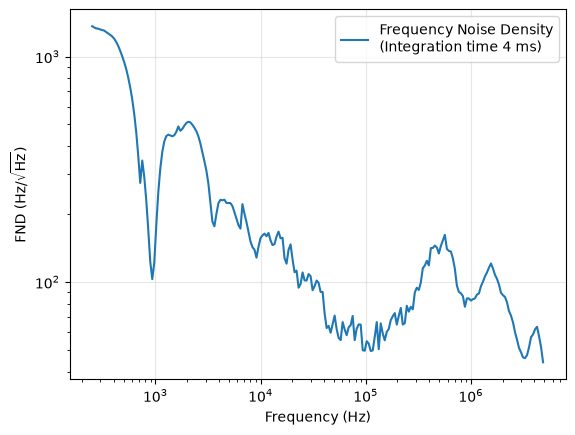

In [21]:
frequency_fluctuations_in_time_Hz = frequency_fluctuations_in_time*1e6
frequencies, psd = lpsd(
    frequency_fluctuations_in_time_Hz,
    fs=1 / np.mean(np.diff(time_locked)),
    Jdes=300,
    Kdes=30,
    Kmin=1,
    xi=0.0,
)

mask = frequencies <= 5e6 # Bandwidth of measurement is 5 MHz
fnd = np.sqrt(psd)
fig, axs = plt.subplots(1, 1)
axs.loglog(frequencies[mask], fnd[mask], label='Frequency Noise Density\n(Integration time 4 ms)')
axs.set_xlabel('Frequency (Hz)')
axs.set_ylabel(r'FND (Hz/$\sqrt{\mathrm{Hz}}$)')
axs.legend()
axs.grid(alpha=0.3)
plt.show()

The oscilloscope we used to acquire the data has a bandwidth of 5 MHz, so we cannot observe frequency noise components above this limit. 
The FND shows us that there most significant components of the frequency noise are concentrated at lower frequencies. This is typically caused by environmental factors such as temperature fluctuations, mechanical vibrations, and acoustic noise. 
We also see some peaks in the FND at frequencies around 100's of kHz, which could be attributed to electronic noise sources in the setup.

## Laser lineshape and linewidth

The optical spectrum can be reconstructed from the accumulated phase associated with the measured frequency fluctuations. The linewidth depends on the record length, sampling bandwidth, and the noise present during the measurement.

A Voigt profile combines a Gaussian contribution, often associated with technical noise or slow frequency drift, with a Lorentzian contribution, often associated with white frequency noise. The fitted components are useful diagnostics, but they do not by themselves prove the origin of the noise.

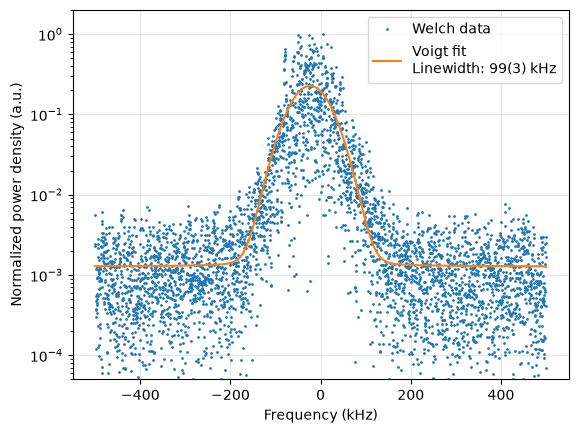

In [22]:

# Use the full record so the Fourier resolution is as fine as possible.
fs = 1 / np.mean(np.diff(time_locked))
s = frequency_fluctuations_in_time_Hz - frequency_fluctuations_in_time_Hz.mean()
e = np.exp(2 * np.pi * 1j * s.cumsum() / fs)


nperseg = len(e)
frequency_resolution = fs / nperseg

freq_fit, spectrum_fit = welch(
    e,
    fs=fs,
    window="hann",
    nperseg=nperseg,
    noverlap=0,
    detrend=False,
    return_onesided=False,
    scaling="density",
)

order = np.argsort(freq_fit)
freq_fit = freq_fit[order]
spectrum_fit = spectrum_fit[order]
spectrum_fit /= spectrum_fit.max()

# Fit the central peak over a range wide enough to constrain both widths.
fit_range = 500e3
fit_mask = np.abs(freq_fit) < fit_range


def voigt(frequency, center, sigma, gamma, amplitude, baseline):
    profile = voigt_profile(frequency - center, sigma, gamma)
    peak_profile = voigt_profile(0.0, sigma, gamma)
    return baseline + amplitude * profile / peak_profile


initial_guess = [freq_fit[np.argmax(spectrum_fit)], 1e3, 1e3, 1.0, 0.0]
bounds = (
    [-fit_range, frequency_resolution / 2, frequency_resolution / 2, 0.0, 0.0],
    [fit_range, fit_range, fit_range, 2.0, 1.0],
)
fit_parameters, fit_covariance = curve_fit(
    voigt,
    freq_fit[fit_mask],
    spectrum_fit[fit_mask],
    p0=initial_guess,
    bounds=bounds,
    maxfev=100_000,
)

center, sigma, gamma, amplitude, baseline = fit_parameters
center_uncertainty, sigma_uncertainty, gamma_uncertainty = np.sqrt(np.diag(fit_covariance))[:3]

# Olivero-Longbothum approximation for the Voigt FWHM.
gaussian_fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma
lorentzian_fwhm = 2 * gamma
linewidth = 0.5346 * lorentzian_fwhm + np.sqrt(
    0.2166 * lorentzian_fwhm**2 + gaussian_fwhm**2
)

def voigt_fwhm(sigma_value, gamma_value):
    gaussian_width = 2 * np.sqrt(2 * np.log(2)) * sigma_value
    lorentzian_width = 2 * gamma_value
    return 0.5346 * lorentzian_width + np.sqrt(
        0.2166 * lorentzian_width**2 + gaussian_width**2
)

fwhm_gradient = np.array([
    (voigt_fwhm(sigma + sigma_uncertainty, gamma) - voigt_fwhm(sigma - sigma_uncertainty, gamma)) / (2 * sigma_uncertainty),
    (voigt_fwhm(sigma, gamma + gamma_uncertainty) - voigt_fwhm(sigma, gamma - gamma_uncertainty)) / (2 * gamma_uncertainty),
])
linewidth_uncertainty = np.sqrt(fwhm_gradient @ fit_covariance[1:3, 1:3] @ fwhm_gradient)

fit_frequency = np.linspace(-fit_range, fit_range, 2000)
fit_spectrum = voigt(fit_frequency, *fit_parameters)
half_max = baseline + amplitude / 2

fig, axs = plt.subplots(1,1)
axs.semilogy(freq_fit[fit_mask] / 1e3, spectrum_fit[fit_mask], ".", markersize=2, label="Welch data")
axs.semilogy(fit_frequency / 1e3, fit_spectrum, label=f"Voigt fit\nLinewidth: {linewidth / 1e3:.0f}({linewidth_uncertainty / 1e3:.0f}) kHz")

axs.set_xlabel("Frequency (kHz)")
axs.set_ylabel("Normalized power density (a.u.)")
axs.set_ylim(5e-5, 2)
axs.grid(alpha=0.3)
axs.legend()
plt.show()